# 모듈 2 · CV 미니프로젝트 — YOLO 객체 탐지 성능 평가 및 최적화

**기간:** 이틀(총 16교시) · **체크포인트:** CP-01~06(첫날), CP-07~10(둘째 날)  
**모델:** 수업에서 활용한 **YOLO26 Nano (`yolo26n.pt`)** · **데이터:** COCO 2017 Validation의 교통 관련 이미지 일부  
**최종 결과물:** 객체 탐지 평가기, 장면 분석기, Validation/Test 평가 결과, 명세서·ADR·분석 문서

> **프로젝트 핵심:** IoU → 1:1 매칭 → TP·FP·FN → Precision·Recall·F1을 직접 구현한 뒤, Confidence Threshold별 결과를 비교하여 활용 상황에 맞는 최종 설정을 스스로 결정합니다.  
> Train/Fine-tuning은 하지 않습니다. `Test`는 CP-10에 도달한 뒤에만 평가합니다.

### 실습 진행 방법

1. 가장 먼저 **00. 환경 설치·프로젝트 폴더 준비** 셀부터 순서대로 실행하세요.
2. 각 CP의 `[학생 구현] TODO`를 작성하고, 바로 아래 검증 셀을 통과한 뒤 다음 CP로 이동하세요.
3. 진행 중 생성된 CSV·JSON·그림은 `outputs/`에 자동 저장됩니다. GPU 세션이 초기화되어도 저장 폴더가 남아 있다면 기존 다운로드와 추론 캐시를 재사용할 수 있습니다.
4. 10개 CP를 완료한 다음 **명세서, ADR, 결과 분석 문서**를 따로 작성합니다. 핵심 실험 결과는 Notebook에 미리 기록합니다.

**자료 출처:** [COCO](https://cocodataset.org/#termsofuse) / [Ultralytics YOLO26](https://docs.ultralytics.com/models/yolo26)  
COCO 원본 이미지의 권리는 원저작자별로 다를 수 있으므로 공개 저장소에 원본 이미지 전체를 재배포하지 마세요.

## 00. 환경 설치와 초기화 복구

GPU 세션을 새로 만들면 이전에 설치한 패키지가 사라질 수 있습니다. **이 첫 번째 코드 셀은 필요한 라이브러리를 한꺼번에 점검하고, 누락되었거나 구버전인 패키지만 설치**합니다. 이후 모든 실습 셀은 이 설치가 끝난 환경을 전제로 동작합니다.

In [1]:
import importlib.util
import importlib.metadata
import subprocess
import sys

# [공통] YOLO26을 지원하는 최신 Ultralytics가 필요합니다.
required = {
    "ultralytics": "ultralytics>=8.4.0",
    "torch": "torch",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "PIL": "Pillow",
    "requests": "requests",
    "tqdm": "tqdm",
}
# 목록을 하나씩 확인해서, 설치되어 있지 않은 패키지만 missing에 모읍니다.
missing = [package for module, package in required.items()
           if module != "ultralytics" and importlib.util.find_spec(module) is None]

# [공통] Ultralytics가 없거나 YOLO26 이전 버전이면 설치·업데이트합니다.
try:
    version = importlib.metadata.version("ultralytics")
    major_minor = tuple(map(int, version.split(".")[:2]))
    if major_minor < (8, 4):
        missing.append(required["ultralytics"])
except importlib.metadata.PackageNotFoundError:
    missing.append(required["ultralytics"])

if missing:
    print("필요한 패키지 설치:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *missing])
else:
    print("필수 패키지가 이미 설치되어 있습니다.")
print("초기 패키지 점검 완료")

필수 패키지가 이미 설치되어 있습니다.
초기 패키지 점검 완료


**실습 폴더는 첫 실행 시 자동으로 생성합니다.** RunPod의 `/workspace`가 존재하면 해당 위치를 우선 사용하며, 다른 환경에서는 현재 작업 폴더 아래에 저장합니다. 컨테이너 자체가 삭제되면 일시 저장 데이터는 유지되지 않을 수 있으므로, 중요 결과는 별도 저장소에도 백업하세요.

In [2]:
from pathlib import Path
import os
import json
import random
import time
import zipfile
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import requests
from tqdm.auto import tqdm
import torch
from ultralytics import YOLO
from ultralytics.utils import ASSETS_URL

# 무작위 결과를 고정하는 숫자입니다. 누가 실행해도 같은 이미지 160장이 뽑히게 합니다.
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)

# [공통] 원하는 저장 경로가 있으면 환경변수 CV_PROJECT_ROOT로 지정할 수 있습니다.
# RunPod처럼 /workspace 폴더가 있으면 그 아래에, 없으면 현재 폴더 아래에 프로젝트 폴더를 둡니다.
default_root = Path('/workspace/cv_yolo_mini') if Path('/workspace').exists() else Path.cwd() / 'cv_yolo_mini'

# 환경변수가 지정되어 있으면 그 경로를 쓰고, 없으면 위에서 정한 기본 경로를 씁니다.
PROJECT_ROOT = Path(os.environ.get('CV_PROJECT_ROOT', str(default_root))).expanduser().resolve()

# 데이터 관련 폴더입니다. 라벨(정답), 이미지, 내려받은 원본 파일, 이미지 목록을 나눠 둡니다.
DATA_DIR = PROJECT_ROOT / 'data'
LABEL_DIR = DATA_DIR / 'labels' / 'val2017'
IMAGE_DIR = DATA_DIR / 'images' / 'val2017'
DOWNLOAD_DIR = DATA_DIR / 'downloads'
MANIFEST_DIR = DATA_DIR / 'manifests'

# 모델 가중치 파일을 두는 폴더입니다.
WEIGHTS_DIR = PROJECT_ROOT / 'weights'

# 결과물 폴더입니다. 예측 저장본, 표, 그림, 보고서를 나눠 둡니다.
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
CACHE_DIR = OUTPUT_DIR / 'cache'
TABLE_DIR = OUTPUT_DIR / 'tables'
FIG_DIR = OUTPUT_DIR / 'figures'
REPORT_DIR = OUTPUT_DIR / 'reports'

# 위에서 정한 폴더를 실제로 만듭니다. 이미 있으면 그대로 둡니다.
for folder in [LABEL_DIR, IMAGE_DIR, DOWNLOAD_DIR, MANIFEST_DIR, WEIGHTS_DIR,
               CACHE_DIR, TABLE_DIR, FIG_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# [공통] 수업에서 사용했던 4개 클래스만 탐지·평가합니다. COCO 모델의 원본 클래스 ID입니다.
# 번호와 이름의 짝입니다. COCO 80개 클래스 중 0, 1, 2, 5번만 씁니다.
TARGET_NAMES = {0: 'person', 1: 'bicycle', 2: 'car', 5: 'bus'}

# 번호만 꺼낸 리스트 [0, 1, 2, 5]입니다.
TARGET_CLASSES = list(TARGET_NAMES)

# 사용할 모델 파일 이름입니다. YOLO26 중 가장 작은 Nano 모델입니다.
MODEL_FILENAME = 'yolo26n.pt'

##### 중요! 추론은 가장 낮은 기준 0.05로 한 번만 하고, 나중에 0.15·0.30·0.60 이상인 예측만 골라 씁니다.
BASE_CONF = 0.05       # Threshold 비교를 위한 가장 낮은 추론 Confidence

# 모델에 넣을 때 이미지의 긴 변을 640픽셀로 맞춥니다.
BASE_SIZE = 640

# 예측 박스와 정답 박스가 이만큼(50%) 이상 겹쳐야 맞힌 것으로 봅니다.
IOU_THRESHOLD = 0.50

# GPU가 있으면 0번 GPU를, 없으면 CPU를 씁니다.
DEVICE = 0 if torch.cuda.is_available() else 'cpu'

# 설정이 제대로 잡혔는지 확인용으로 출력합니다.
print('프로젝트 경로:', PROJECT_ROOT)
print('사용 장치:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU (GPU 사용 권장)')
print('Ultralytics:', __import__('ultralytics').__version__)
print('저장 폴더 준비 완료')

프로젝트 경로: /workspace/cv_yolo_mini
사용 장치: NVIDIA GeForce RTX 4090
Ultralytics: 8.4.218
저장 폴더 준비 완료


### 저장 위치 안내

- `data/labels`·`data/images`: 정답 라벨과 COCO 이미지  
- `data/manifests`: Validation과 별도 보류 Test의 이미지 목록  
- `weights`: 사전학습 YOLO 가중치  
- `outputs/cache`: 반복 추론 시간을 줄이기 위한 모델 예측 결과  
- `outputs/tables`, `outputs/figures`, `outputs/reports`: 성능표·시각화·최종 분석 자료

처음 실행할 때 파일이 없으면 자동 다운로드·생성하며, 이미 있으면 재사용합니다. **다른 폴더에 임의로 파일을 옮기지 마세요.**

# Day 1 — 객체 탐지 성능 평가기 구현

첫날은 CP-01~06을 진행합니다. **정답과 예측을 직접 매칭하는 평가기**가 완성되면 Day 2에서 설정 변경 실험에 그대로 사용할 수 있습니다.

---
## CP-01. COCO 데이터셋 및 Annotation 구조 확인

교통 관련 COCO 검증 이미지의 정답 파일을 준비하고, 데이터 구조를 이해합니다. 학습에 사용한 COCO Train이 아닌 **COCO 2017 Validation 이미지**에서 일부를 추출하며, 그 안에서 Validation과 보류 Test를 다시 구분합니다.

**데이터 자동 준비 코드(공통).** 공식 Ultralytics의 COCO 라벨 ZIP에서 `val2017` 라벨만 추출하고, 교통 관련 클래스의 이미지 160장을 선택합니다. 이미지 원본은 COCO 서버에서 필요한 것만 내려받습니다. 네트워크 문제로 일부 파일이 누락되면 셀을 다시 실행해 누락분만 받아옵니다.

In [4]:
from concurrent.futures import ThreadPoolExecutor, as_completed   # 여러 파일을 동시에 내려받는 도구

# 내려받을 라벨 ZIP 파일의 저장 위치입니다.
LABEL_ZIP = DOWNLOAD_DIR / 'coco2017labels.zip'

# 어떤 이미지 160장을 골랐는지 적어 둘 목록 파일입니다.
MANIFEST_PATH = MANIFEST_DIR / 'coco_traffic_160_seed2026.json'

# Validation은 120장, 마지막까지 열지 않는 Test는 40장입니다.
NUM_VALIDATION = 120
NUM_HOLDOUT_TEST = 40


def download_binary(url, dest, timeout=(15, 90), attempts=3):
    """[공통] 이미 받은 정상 파일은 재사용하고, 실패한 다운로드만 다시 시도합니다."""
    # 저장할 위치를 경로 객체로 바꾸고, 상위 폴더가 없으면 만듭니다.
    dest = Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)

    # 파일이 이미 있고 크기가 1KB보다 크면 정상 파일로 보고 다시 받지 않습니다.
    if dest.is_file() and dest.stat().st_size > 1024:
        return dest

    # 실패하면 최대 3번까지 다시 시도합니다.
    for attempt in range(1, attempts + 1):
        # 받는 동안에는 이름 끝에 .part가 붙은 임시 파일에 씁니다.
        temporary = dest.with_suffix(dest.suffix + '.part')
        try:
            # 주소에 접속해서 파일을 조금씩 나눠 받습니다.
            with requests.get(url, stream=True, timeout=timeout) as response:
                # 접속에 실패했으면(404 등) 여기서 오류를 냅니다.
                response.raise_for_status()

                # 1MB씩 받아서 임시 파일에 이어 씁니다.
                with temporary.open('wb') as fout:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            fout.write(chunk)

            # 받은 파일이 1KB보다 작으면 잘못 받은 것으로 보고 오류를 냅니다.
            if temporary.stat().st_size < 1024:
                raise ValueError('다운로드된 파일의 크기가 너무 작습니다.')

            # 다 받았으면 임시 파일의 이름을 진짜 이름으로 바꾸고 끝냅니다.
            temporary.replace(dest)
            return dest
        except (requests.RequestException, OSError, ValueError):
            # 실패하면 임시 파일을 지웁니다.
            temporary.unlink(missing_ok=True)

            # 마지막 시도까지 실패했으면 오류를 그대로 올립니다.
            if attempt == attempts:
                raise

            # 아니면 잠시 기다린 뒤 다시 시도합니다.
            time.sleep(attempt)


# 압축을 이미 풀었다는 표시 파일이 없을 때만 아래를 실행합니다. 즉 처음 한 번만 실행됩니다.
if not (LABEL_DIR / '.extraction_complete').exists():
    print('COCO 검증 라벨 다운로드·압축 해제 (최초 1회)')

    # Ultralytics 공식 저장소에서 COCO 라벨 ZIP을 내려받습니다.
    download_binary(f'{ASSETS_URL}/coco2017labels.zip', LABEL_ZIP, timeout=(20, 180))

    # [공통] 수만 장의 Train 라벨은 압축 해제하지 않고 Val 라벨만 가져옵니다.
    with zipfile.ZipFile(LABEL_ZIP) as archive:
        # ZIP 안의 파일 중 val2017 폴더에 있는 .txt 라벨만 고릅니다.
        label_members = [name for name in archive.namelist()
                         if '/labels/val2017/' in ('/' + name.replace(chr(92), '/'))
                         and name.endswith('.txt')]

        # 고른 라벨이 1000개보다 적으면 ZIP이 잘못된 것으로 보고 멈춥니다.
        if len(label_members) < 1000:
            raise RuntimeError('ZIP에서 COCO val2017 정답 라벨을 찾을 수 없습니다.')

        # 고른 라벨 파일을 하나씩 꺼내 라벨 폴더에 저장합니다.
        for name in tqdm(label_members, desc='COCO Val 라벨 추출'):
            (LABEL_DIR / Path(name).name).write_bytes(archive.read(name))

        # 다 끝났다는 표시 파일을 남깁니다. 다음에 실행하면 이 블록을 건너뜁니다.
        (LABEL_DIR / '.extraction_complete').write_text(str(len(label_members)), encoding='utf-8')


def read_class_set(label_path):
    """[공통] YOLO 라벨 첫 열의 클래스 번호를 확인합니다."""
    # 이 이미지에 나오는 클래스 번호를 모을 빈 집합입니다.
    classes = set()

    # 라벨 파일을 한 줄씩 읽습니다. 한 줄이 객체 하나입니다.
    for line in label_path.read_text(encoding='utf-8').splitlines():
        # 한 줄을 띄어쓰기로 나눕니다. 예: "0 0.48 0.63 0.69 0.71"
        parts = line.split()

        # 맨 앞 숫자가 클래스 번호이므로 그것만 집합에 넣습니다.
        if parts:
            classes.add(int(parts[0]))

    # 예: 사람과 자동차가 있는 이미지라면 {0, 2}를 돌려줍니다.
    return classes


# 이미지 목록 파일이 이미 있으면 그것을 읽어서 씁니다. 다시 고르지 않으므로 항상 같은 160장이 됩니다.
if MANIFEST_PATH.exists():
    split_manifest = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
else:
    # 라벨 파일 전체를 이름 순서로 나열합니다.
    label_files = sorted(LABEL_DIR.glob('*.txt'))

    # 이미지 이름마다 그 안에 나오는 클래스 번호 집합을 짝지어 둡니다. 예: {'000000001234': {0, 2}}
    groups = {p.stem: read_class_set(p) for p in label_files}

    # SEED로 고정한 무작위 도구를 만듭니다. 누가 실행해도 같은 순서로 섞입니다.
    rng = random.Random(SEED)

    # 고른 이미지 이름을 담을 리스트와, 중복을 막기 위한 집합입니다.
    chosen = []
    selected_ids = set()

    # [공통] 출현 빈도가 낮은 클래스부터 순회하여 각 종류가 골고루 포함되게 합니다.
    ##### 중요! 버스(5) → 자전거(1) → 자동차(2) → 사람(0) 순서로, 그 클래스가 나오는 이미지를 35장씩 고릅니다.
    for class_id in (5, 1, 2, 0):
        # 이 클래스가 들어 있고 아직 고르지 않은 이미지를 후보로 모읍니다.
        candidates = [stem for stem, classes in groups.items() if class_id in classes and stem not in selected_ids]

        # 후보를 무작위로 섞습니다.
        rng.shuffle(candidates)

        # 앞에서 35장을 골라 담습니다.
        for stem in candidates[:35]:
            chosen.append(stem)
            selected_ids.add(stem)

    # 4개 클래스 중 하나라도 들어 있고 아직 고르지 않은 이미지를 후보로 모읍니다.
    positive_candidates = [stem for stem, classes in groups.items()
                           if classes.intersection(TARGET_CLASSES) and stem not in selected_ids]
    rng.shuffle(positive_candidates)

    # 위에서 고른 것이 140장보다 적을 때만 여기서 140장까지 채웁니다.
    for stem in positive_candidates:
        if len(chosen) >= 140:
            break
        chosen.append(stem)
        selected_ids.add(stem)

    # 4개 클래스가 하나도 없는 이미지를 후보로 모읍니다.
    negative_candidates = [stem for stem, classes in groups.items()
                           if not classes.intersection(TARGET_CLASSES) and stem not in selected_ids]
    rng.shuffle(negative_candidates)

    # [공통] 목표 클래스가 전혀 없는 이미지는 오탐지 검증에 유용합니다.
    # 그런 이미지를 20장 추가합니다. 여기까지 140 + 20 = 160장입니다.
    chosen.extend(negative_candidates[:20])

    # 고른 수가 160장이 아니면 멈춥니다.
    if len(chosen) != NUM_VALIDATION + NUM_HOLDOUT_TEST:
        raise RuntimeError(f'데이터 수가 예상과 다릅니다: {len(chosen)}장')

    # 160장 전체를 한 번 더 섞습니다. 버스 이미지가 앞쪽에만 몰리지 않게 하기 위해서입니다.
    rng.shuffle(chosen)

    # 앞의 120장은 Validation, 나머지 40장은 Test로 나눠 목록을 만듭니다.
    split_manifest = {
        'source': 'COCO2017 val2017 (held-out partition; NOT official COCO test2017)',
        'seed': SEED,
        'classes': TARGET_NAMES,
        'validation': chosen[:NUM_VALIDATION],
        'test': chosen[NUM_VALIDATION:],
    }

    # 목록을 파일로 저장합니다. 다음 실행부터는 이 파일을 읽습니다.
    MANIFEST_PATH.write_text(json.dumps(split_manifest, ensure_ascii=False, indent=2), encoding='utf-8')


def ensure_image(stem):
    # 이 이미지가 저장될 경로입니다.
    image_file = IMAGE_DIR / f'{stem}.jpg'

    # 파일이 이미 있으면 정상적으로 열리는지 검사하고, 정상이면 그대로 씁니다.
    if image_file.is_file() and image_file.stat().st_size > 1024:
        try:
            with Image.open(image_file) as im:
                im.verify()
            return image_file
        except (OSError, ValueError):
            # 깨진 파일이면 지우고 아래에서 다시 받습니다.
            image_file.unlink(missing_ok=True)

    # COCO 공식 서버에서 이미지를 내려받습니다.
    url = f'http://images.cocodataset.org/val2017/{stem}.jpg'
    download_binary(url, image_file, timeout=(15, 60))

    # 받은 이미지가 정상적으로 열리는지 검사합니다.
    with Image.open(image_file) as im:
        im.verify()
    return image_file


# Validation과 Test의 이미지 이름을 합쳐 160개 목록을 만듭니다.
all_stems = split_manifest['validation'] + split_manifest['test']

# 그중 아직 없거나 크기가 너무 작은 이미지만 골라냅니다.
missing_images = [stem for stem in all_stems
                  if not (IMAGE_DIR / f'{stem}.jpg').exists() or (IMAGE_DIR / f'{stem}.jpg').stat().st_size <= 1024]

# 빠진 이미지가 있을 때만 내려받습니다.
if missing_images:
    print(f'COCO 검증 이미지 누락분 {len(missing_images)}장 다운로드')

    # 실패한 이미지를 적어 둘 리스트입니다.
    failures = []

    # 한 번에 6장씩 동시에 내려받습니다.
    with ThreadPoolExecutor(max_workers=6) as pool:
        # 빠진 이미지마다 내려받기 작업을 하나씩 맡깁니다.
        futures = {pool.submit(ensure_image, stem): stem for stem in missing_images}

        # 끝나는 순서대로 결과를 확인하고, 실패한 것은 기록합니다.
        for future in tqdm(as_completed(futures), total=len(futures), desc='이미지 준비'):
            try:
                future.result()
            except Exception as exc:
                failures.append((futures[future], str(exc)))

    # 하나라도 실패했으면 다시 실행하라고 알리며 멈춥니다.
    if failures:
        raise RuntimeError(f'이미지 {len(failures)}장 다운로드 실패. 인터넷 연결 확인 후 이 셀을 재실행하세요. 예: {failures[:2]}')

# 최종 장수를 출력합니다.
print('Validation:', len(split_manifest['validation']), '장 / 별도 보류 Test:', len(split_manifest['test']), '장')
print('이미지·라벨 자동 준비 완료')

COCO 검증 이미지 누락분 160장 다운로드


이미지 준비:   0%|          | 0/160 [00:00<?, ?it/s]

Validation: 120 장 / 별도 보류 Test: 40 장
이미지·라벨 자동 준비 완료


**정답 좌표 확인(공통).** COCO 라벨은 정규화된 `(center_x, center_y, width, height)` 형태로 저장되어 있습니다. 실제 좌표 `(x1, y1, x2, y2)`로 변환하는 코드는 제공되며, 학생들은 변환된 좌표와 클래스 분포를 확인합니다.

,class,gt_count
0,person,383
1,bicycle,75
2,car,204
3,bus,43


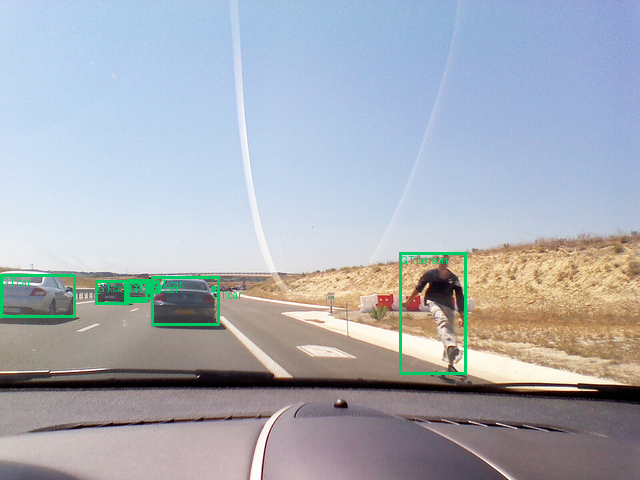

In [5]:
def make_records(stems):
    # 이미지 이름마다 이미지 경로와 라벨 경로를 묶은 딕셔너리를 만듭니다.
    return [{'image_id': str(stem), 'image_path': str(IMAGE_DIR / f'{stem}.jpg'),
             'label_path': str(LABEL_DIR / f'{stem}.txt')} for stem in stems]

# Validation 120장과 Test 40장의 정보 목록을 만듭니다.
val_records = make_records(split_manifest['validation'])
test_records = make_records(split_manifest['test'])   # CP-10까지 정답·예측 결과는 열어보지 않습니다.


def load_ground_truth(record):
    """[공통] YOLO 형식 정답 라벨을 실제 이미지 픽셀 좌표로 변환합니다."""
    # 이미지를 열어 가로·세로 픽셀 수를 읽습니다.
    with Image.open(record['image_path']) as im:
        width, height = im.size

    # 라벨 파일을 줄 단위로 읽습니다. 파일이 없으면 빈 리스트로 둡니다.
    label_file = Path(record['label_path'])
    rows = label_file.read_text(encoding='utf-8').splitlines() if label_file.exists() else []

    # 변환한 정답 박스를 담을 리스트입니다.
    outputs = []
    for line in rows:
        # 한 줄을 띄어쓰기로 나눕니다. 숫자가 5개가 아니면 건너뜁니다.
        values = line.split()
        if len(values) != 5:
            continue

        # 맨 앞 숫자가 클래스 번호입니다. 4개 대상 클래스가 아니면 건너뜁니다.
        class_id = int(values[0])
        if class_id not in TARGET_CLASSES:
            continue

        # 나머지 네 숫자는 중심 x, 중심 y, 너비, 높이입니다. 모두 0~1 사이의 비율입니다.
        cx, cy, bw, bh = map(float, values[1:])

        ##### 중요! 중심에서 너비의 절반을 빼면 왼쪽 끝 비율이 되고, 이미지 가로 픽셀 수를 곱하면 픽셀 좌표가 됩니다.
        x1 = max(0., (cx - bw / 2) * width)

        # 같은 방법으로 위쪽 끝, 오른쪽 끝, 아래쪽 끝을 구합니다. max와 min은 이미지 밖으로 나가지 않게 막습니다.
        y1 = max(0., (cy - bh / 2) * height)
        x2 = min(float(width), (cx + bw / 2) * width)
        y2 = min(float(height), (cy + bh / 2) * height)

        # 클래스 번호와 [왼쪽, 위, 오른쪽, 아래] 좌표를 딕셔너리로 담습니다.
        outputs.append({'cls': class_id, 'xyxy': [x1, y1, x2, y2]})
    return outputs


def draw_boxes(record, ground_truth, predictions=None, statuses=None, missed_gt_indices=None):
    """[공통] 녹색=정답, 주황색=놓친 정답(FN), 파란색=예측 TP, 빨간색=예측 FP입니다.

    missed_gt_indices에 match_detections() 결과의 'missed_gt_indices'를 넘기면
    모델이 놓친 정답 박스를 주황색(FN)으로 구분해서 그립니다. 넘기지 않으면 정답은 모두 녹색입니다.
    """
    # 이미지를 열고, 그 위에 그릴 준비를 합니다.
    canvas = Image.open(record['image_path']).convert('RGB')
    draw = ImageDraw.Draw(canvas)

    # 모델이 놓친 정답의 번호를 집합으로 만듭니다. 넘기지 않았으면 빈 집합입니다.
    missed = set(missed_gt_indices or [])

    # 정답 박스를 하나씩 그립니다.
    for gt_idx, gt in enumerate(ground_truth):
        # 놓친 정답이면 주황색에 FN, 아니면 녹색에 GT라고 표시합니다.
        is_missed = gt_idx in missed
        gt_color = '#ff9900' if is_missed else '#00cc66'
        gt_tag = 'FN' if is_missed else 'GT'

        # 박스를 그리고, 왼쪽 위에 표시와 클래스 이름을 적습니다.
        draw.rectangle(gt['xyxy'], outline=gt_color, width=4 if is_missed else 3)
        draw.text((gt['xyxy'][0] + 2, gt['xyxy'][1] + 2), f"{gt_tag}:{TARGET_NAMES[gt['cls']]}", fill=gt_color)

    # 예측 박스를 하나씩 그립니다. 예측을 넘기지 않았으면 이 부분은 건너뜁니다.
    for idx, pred in enumerate(predictions or []):
        # 틀린 예측(FP)이면 빨간색, 아니면 파란색입니다.
        state = statuses[idx] if statuses else 'pred'
        color = '#ee3322' if state == 'FP' else '#2575ff'

        # 박스를 그리고, 클래스 이름과 Confidence를 적습니다.
        draw.rectangle(pred['xyxy'], outline=color, width=3)
        draw.text((pred['xyxy'][0] + 2, pred['xyxy'][1] + 17),
                  f"{TARGET_NAMES[pred['cls']]} {pred['confidence']:.2f}", fill=color)
    return canvas

# Validation 데이터의 클래스 분포만 먼저 분석합니다.
# Validation 120장 각각의 정답 박스를 읽어 옵니다.
val_labels = [load_ground_truth(r) for r in val_records]

# 모든 정답 박스의 클래스 번호를 모아 클래스별 개수를 셉니다.
count_by_class = Counter(gt['cls'] for labels in val_labels for gt in labels)

# 클래스 이름과 개수를 표로 만들어 보여 주고, CSV 파일로 저장합니다.
class_table = pd.DataFrame([{'class': TARGET_NAMES[k], 'gt_count': count_by_class[k]}
                            for k in TARGET_CLASSES])
display(class_table)
class_table.to_csv(TABLE_DIR / 'cp01_validation_class_counts.csv', index=False)

# 정답 박스가 하나라도 있는 첫 번째 이미지를 고릅니다.
record = next(r for r in val_records if load_ground_truth(r))

# 그 이미지에 정답 박스를 그립니다.
example_image = draw_boxes(record, load_ground_truth(record))

# 가로가 800픽셀을 넘으면 비율을 유지한 채 줄여서 보여 줍니다.
display(example_image.resize((min(800, example_image.width), int(example_image.height * min(800, example_image.width) / example_image.width))))

**객체 크기 분포 확인(공통).** 같은 클래스라도 객체가 작으면 탐지하기 어렵습니다. 정답 박스의 면적을 기준으로 small·medium·large로 나누어 클래스별 개수를 확인합니다. COCO 평가에서 쓰는 면적 기준(32², 96² 픽셀)을 박스 면적에 적용한 교육용 구분이며, 코드는 제공됩니다. 학생들은 표를 읽고 아래 해석 기록을 작성합니다.

In [6]:
# [공통] 정답 박스의 크기 분포 — 박스 면적(픽셀²) 기준으로 small / medium / large를 구분합니다.
# 표의 열을 이 순서로 놓기 위한 리스트입니다.
SIZE_ORDER = ['small', 'medium', 'large']


def size_bucket(xyxy):
    """[공통] 면적이 32² 미만이면 small, 96² 미만이면 medium, 그 이상이면 large입니다."""
    ##### 중요! 박스 면적은 (오른쪽 − 왼쪽) × (아래 − 위)입니다. 단위는 픽셀²입니다.
    area = max(0.0, xyxy[2] - xyxy[0]) * max(0.0, xyxy[3] - xyxy[1])

    # 면적이 1024픽셀²(32×32)보다 작으면 small입니다.
    if area < 32 ** 2:
        return 'small'

    # 면적이 9216픽셀²(96×96)보다 작으면 medium입니다.
    if area < 96 ** 2:
        return 'medium'

    # 그보다 크면 large입니다.
    return 'large'


# Validation의 모든 정답 박스에 대해 클래스 이름과 크기 구분을 한 줄씩 만듭니다.
size_rows = [{'class': TARGET_NAMES[gt['cls']], 'size': size_bucket(gt['xyxy'])}
             for labels in val_labels for gt in labels]

# 클래스와 크기별로 개수를 세어, 행은 클래스이고 열은 small·medium·large인 표로 만듭니다.
size_table = (pd.DataFrame(size_rows, columns=['class', 'size'])
              .groupby(['class', 'size']).size().unstack(fill_value=0)
              .reindex(index=[TARGET_NAMES[k] for k in TARGET_CLASSES], columns=SIZE_ORDER, fill_value=0))

# 표의 열 묶음 이름('size')을 지워 표를 깔끔하게 합니다.
size_table.columns.name = None

# 세 열을 더해 클래스별 전체 개수를 total 열로 추가합니다.
size_table['total'] = size_table[SIZE_ORDER].sum(axis=1)

# small_ratio: 해당 클래스의 정답 객체 중 작은 객체가 차지하는 비율
# small 개수를 total로 나눕니다. total이 0인 클래스는 0으로 나누지 않도록 처리합니다.
size_table['small_ratio'] = (size_table['small'] / size_table['total'].replace(0, np.nan)).fillna(0.0).round(3)

# 표를 보여 주고 CSV 파일로 저장합니다.
display(size_table)
size_table.to_csv(TABLE_DIR / 'cp01_validation_size_counts.csv')

,small,medium,large,total,small_ratio
class,,,,,
person,169,135,79,383,0.441
bicycle,25,33,17,75,0.333
car,100,87,17,204,0.490
bus,4,4,35,43,0.093


**결과 해석 기록 — CP-01**

- 정답 객체 수가 가장 많은 클래스와 가장 적은 클래스는 무엇인가요? 개수가 적은 클래스의 Precision·Recall을 해석할 때 무엇을 주의해야 할까요?
  가장 많은 클래스는 person(383개)이고, 가장 적은 클래스는 bus(43개)다. 두 클래스의 차이는 약 9배다. 그다음은 car(204개), bicycle(75개) 순서다. 개수가 적은 클래스는 객체 하나가 지표에 주는 영향이 크다. bus는 정답이 43개라서 하나를 더 놓칠 때마다 Recall이 약 2.3%p 떨어지지만, person은 383개라서 약 0.26%p만 떨어진다. 따라서 bus와 bicycle의 지표가 몇 %p 달라진 것은 객체 한두 개의 차이일 수 있으므로, 비율만 보지 말고 TP·FP·FN의 개수를 함께 확인해야 한다.

- 작은 객체(small)의 비율이 가장 높은 클래스는 무엇인가요?
  car가 0.490으로 가장 높다. car 정답 204개 중 100개가 small이다. 그다음은 person(0.441), bicycle(0.333) 순서이고, bus는 0.093으로 가장 낮다. bus는 43개 중 35개(약 81%)가 large인 반면, car는 204개 중 17개(약 8%)만 large다.

- 네 클래스 중 YOLO가 가장 놓치기 쉬울 것으로 예상하는 클래스는 무엇이며, 그렇게 예상한 근거는 무엇인가요?
  car를 가장 놓치기 쉬울 것으로 예상한다. 작은 객체의 비율이 가장 높고(0.490), 큰 객체는 약 8%뿐이기 때문이다. 멀리 있는 자동차가 작게 찍힌 경우가 많다는 뜻이므로 Recall이 네 클래스 중 가장 낮을 것으로 본다. person도 small 비율이 0.441로 비슷하고 small 객체의 개수는 169개로 가장 많으므로, 놓친 객체(FN)의 개수 자체는 person에서 가장 많이 나올 수 있다. 반대로 bus는 대부분이 큰 객체라서 가장 잘 찾을 것으로 예상한다. 다만 이 예상은 객체의 크기만 본 것이고, 가려짐이나 겹침 같은 요인은 이 표로 알 수 없다. 실제 결과는 CP-08에서 클래스별 Recall과 FN 개수로 확인한다.

**[CP-01 완료 기준]** COCO Validation 이미지와 정답 Bounding Box를 확인하고, 클래스별 개수와 객체 크기 분포를 출력한 뒤 해석 기록을 작성합니다. Test 정답은 아직 분석하지 않습니다.

---
## CP-02. YOLO 추론·결과 추출·Bounding Box 시각화

수업에서 사용한 YOLO26 Nano를 로딩합니다. 예측 결과인 `xyxy`, `conf`, `cls`를 읽어 각 객체를 공통 형식으로 정리하고 이미지에 표시합니다.

**사전학습 가중치 자동 준비(공통).** `weights/yolo26n.pt`가 없다면 Ultralytics가 자동으로 내려받습니다. 이미 저장된 모델은 다시 다운로드하지 않으며, GPU가 있으면 CUDA 추론을 사용합니다.

In [7]:
# [공통] 가중치를 항상 weights/ 폴더 아래에 저장합니다.
model_path = WEIGHTS_DIR / MODEL_FILENAME
if not model_path.exists():
    previous_dir = Path.cwd()
    try:
        os.chdir(WEIGHTS_DIR)
        model = YOLO(MODEL_FILENAME)       # Ultralytics 공식 사전학습 가중치 자동 다운로드
    finally:
        os.chdir(previous_dir)
    if not model_path.exists():
        raise RuntimeError('YOLO 가중치 다운로드가 완료되지 않았습니다. 네트워크 확인 후 다시 실행하세요.')
else:
    model = YOLO(str(model_path))

print('사용 가중치:', model_path, ' / 장치:', DEVICE)

사용 가중치: /workspace/cv_yolo_mini/weights/yolo26n.pt  / 장치: 0


**학생 핵심 구현.** Ultralytics `Results`에서 `boxes.xyxy`, `boxes.conf`, `boxes.cls`를 추출해 이후 평가기에서 재사용할 리스트로 변환합니다. 모든 출력은 이미지 픽셀 단위의 박스 좌표를 사용합니다.

샘플 객체 탐지 수: 6


,cls,confidence,xyxy
0,0,0.820006,"[403.738953, 250.469223, 468.119507, 376.89209]"
1,2,0.816460,"[149.473785, 276.615967, 216.524933, 328.588684]"
2,2,0.808829,"[0.195747, 269.631317, 75.064865, 321.001068]"
3,2,0.609840,"[94.331573, 279.906738, 129.270966, 304.507446]"
4,2,0.473539,"[125.942406, 280.588928, 153.758759, 301.69342]"
5,2,0.151847,"[230.746796, 283.706238, 246.86853, 293.473816]"


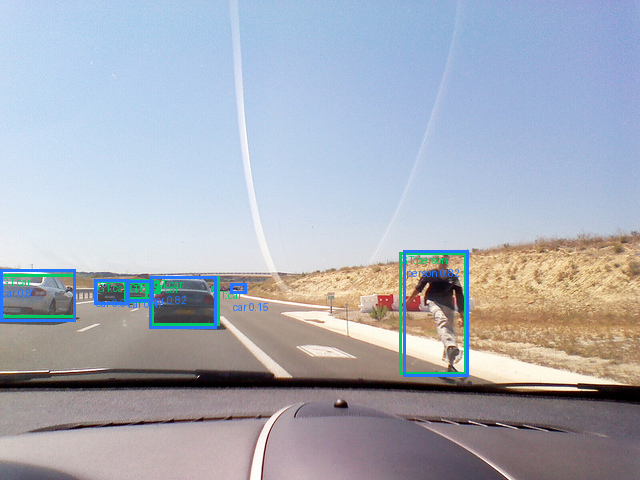

In [11]:
# [학생 구현] CP-02 — YOLO 출력 구조를 공통 딕셔너리 형태로 변환

def extract_predictions(result):
    """예측 1건 = {'cls': int, 'confidence': float, 'xyxy': [x1,y1,x2,y2]}"""
    # ### 1. YOLO가 반환한 박스 좌표, confidence, class ID를 CPU/리스트로 변환합니다.
    # 박스 좌표를 꺼냅니다. 박스 하나가 [왼쪽, 위, 오른쪽, 아래] 숫자 4개입니다.
    boxes_xyxy = result.boxes.xyxy.cpu().tolist()

    # 박스마다 모델이 얼마나 확신하는지를 나타내는 Confidence(0~1)를 꺼냅니다.
    scores = result.boxes.conf.cpu().tolist()

    # 박스마다 예측한 클래스 번호를 꺼냅니다. 2.0처럼 소수 형태로 나옵니다.
    classes = result.boxes.cls.cpu().tolist()

    # ### 2. 각 검출을 하나의 딕셔너리로 정리합니다.
    # 예측을 하나씩 담을 빈 리스트입니다.
    rows = []

    # 같은 순서에 있는 좌표, Confidence, 클래스를 하나씩 묶어서 꺼냅니다.
    for coords, score, cls in zip(boxes_xyxy, scores, classes):
        ##### 중요! 정답과 같은 형식('cls', 'xyxy')으로 만들고 'confidence'만 더합니다. 형식이 같아야 CP-03부터 정답과 비교할 수 있습니다.
        rows.append({'cls': int(cls), 'confidence': float(score),
                     'xyxy': [float(v) for v in coords]})
    return rows


# CP-01에서 본 예시 이미지를 모델에 넣습니다. predict는 이미지마다 결과를 하나씩 담은 리스트를 주므로 [0]으로 첫 번째를 꺼냅니다.
example_result = model.predict(record['image_path'], conf=0.15, imgsz=BASE_SIZE,
                               classes=TARGET_CLASSES, device=DEVICE, verbose=False)[0]

# 지안님이 만든 함수로 YOLO 결과를 딕셔너리 리스트로 바꿉니다.
example_predictions = extract_predictions(example_result)

# 모든 예측이 키 3개를 정확히 가지고 있고 좌표가 4개인지 확인합니다.
assert all(set(p) == {'cls', 'confidence', 'xyxy'} and len(p['xyxy']) == 4 for p in example_predictions)

# 탐지한 객체 수를 출력하고, 앞의 10개를 표로 보여 줍니다.
print('샘플 객체 탐지 수:', len(example_predictions))
display(pd.DataFrame(example_predictions).head(10))

# 이미지 위에 정답(녹색)과 예측(파란색)을 함께 그려서 보여 줍니다.
display(draw_boxes(record, load_ground_truth(record), example_predictions))

**[CP-02 완료 기준]** YOLO 예측 결과를 정리해 이미지에 시각화하고, 추론 클래스·좌표·Confidence를 확인합니다.

---
## CP-03. IoU 계산 함수 구현

두 Bounding Box의 교집합과 합집합 면적을 계산하여 `IoU = 교집합 / 합집합`을 구현합니다. 이 코드는 다음 매칭 단계에서 직접 사용됩니다.

**핵심 알고리즘 구현.** 두 박스의 `(x1, y1, x2, y2)`에서 교집합의 좌상단·우하단 좌표를 구한 뒤 넓이를 계산합니다. 겹침이 없으면 IoU는 0, 두 박스가 동일하면 1이어야 합니다.

In [12]:
# [학생 구현] CP-03 — Bounding Box IoU 함수

def calculate_iou(box_a, box_b):
    """[x1, y1, x2, y2] 두 박스의 IoU를 0~1 사이 실수로 반환합니다."""
    # ### 1. 교집합 좌표 = 왼쪽 위는 max, 오른쪽 아래는 min
    # 겹치는 영역의 왼쪽 끝은 두 박스의 왼쪽 끝 중 더 오른쪽에 있는 값입니다.
    x_left = max(box_a[0], box_b[0])

    # 겹치는 영역의 위쪽 끝은 두 박스의 위쪽 끝 중 더 아래에 있는 값입니다.
    y_top = max(box_a[1], box_b[1])

    # 겹치는 영역의 오른쪽 끝은 두 박스의 오른쪽 끝 중 더 왼쪽에 있는 값입니다.
    x_right = min(box_a[2], box_b[2])

    # 겹치는 영역의 아래쪽 끝은 두 박스의 아래쪽 끝 중 더 위에 있는 값입니다.
    y_bottom = min(box_a[3], box_b[3])

    # ### 2. 겹치지 않으면 너비/높이를 0으로 처리
    ##### 중요! 두 박스가 떨어져 있으면 (오른쪽 − 왼쪽)이 음수가 됩니다. max(0.0, ...)으로 0으로 바꿔야 합니다.
    inter_w = max(0.0, x_right - x_left)

    # 높이도 같은 방법으로 음수가 되지 않게 합니다.
    inter_h = max(0.0, y_bottom - y_top)

    # 겹치는 영역의 넓이는 너비 × 높이입니다.
    intersection = inter_w * inter_h

    # ### 3. 두 박스의 면적과 합집합 계산
    # 박스 A와 박스 B 각각의 넓이를 구합니다.
    area_a = max(0.0, box_a[2] - box_a[0]) * max(0.0, box_a[3] - box_a[1])
    area_b = max(0.0, box_b[2] - box_b[0]) * max(0.0, box_b[3] - box_b[1])

    # 두 넓이를 더하면 겹치는 부분이 두 번 들어가므로 한 번 뺍니다.
    union = area_a + area_b - intersection

    # 겹치는 넓이를 합친 넓이로 나눕니다. 합친 넓이가 0이면 나눌 수 없으므로 0을 돌려줍니다.
    return intersection / union if union > 0 else 0.0

**자기 검증(공통).** 숫자만 있는 간단한 예제부터 테스트하면 모델과 데이터에 관계없이 구현이 맞는지 확인할 수 있습니다. 셀에서 오류가 발생한다면 CP-03 계산을 수정하세요.

In [13]:
# [공통] 직접 계산 가능한 예제 (기대값은 미리 고정)
assert abs(calculate_iou([0, 0, 10, 10], [0, 0, 10, 10]) - 1.0) < 1e-8
assert calculate_iou([0, 0, 10, 10], [20, 20, 30, 30]) == 0.0
assert abs(calculate_iou([0, 0, 10, 10], [5, 5, 15, 15]) - 25 / 175) < 1e-8
assert calculate_iou([0, 0, 0, 0], [0, 0, 10, 10]) == 0.0
print('CP-03 IoU 단위 테스트 4건 통과')

CP-03 IoU 단위 테스트 4건 통과


**[CP-03 완료 기준]** `calculate_iou()`를 직접 구현하고 4개 IoU 단위 테스트를 모두 통과합니다.

---
## CP-04. 예측–정답 1:1 매칭 알고리즘 구현

예측을 Confidence 내림차순으로 처리하여 같은 클래스의 아직 매칭되지 않은 정답 중 가장 IoU가 높은 박스를 찾습니다. 하나의 정답은 반드시 **한 예측에만** 매칭합니다.

**핵심 알고리즘 구현.** IoU가 0.5 이상이고 클래스도 같으면 TP, 매칭하지 못한 예측은 FP입니다. 모든 예측을 처리한 후 남은 정답은 FN으로 기록합니다. 중복 매칭 방지가 이번 프로젝트에서 가장 중요한 부분 중 하나입니다.

In [14]:
# [학생 구현] CP-04 — 예측-정답 1:1 매칭

def match_detections(predictions, ground_truth, iou_threshold=0.5):
    """TP/FP 예측 상태와 매칭되지 않은 GT 인덱스를 반환합니다."""
    # 이미 짝이 정해진 정답의 번호를 모아 두는 집합입니다.
    matched_gt = set()

    # 예측마다 TP인지 FP인지 기록할 리스트입니다.
    pred_statuses = []

    # ### 1. 점수가 높은 예측부터 매칭합니다. 원래 인덱스를 유지해야 합니다.
    # 예측에 원래 번호를 붙인 뒤, Confidence가 높은 순서로 정렬합니다.
    ordered = sorted(enumerate(predictions), key=lambda x: x[1]['confidence'], reverse=True)

    # 정렬된 순서대로 예측을 하나씩 처리합니다. pred_idx는 정렬하기 전의 원래 번호입니다.
    for pred_idx, pred in ordered:
        # 이 예측과 가장 많이 겹치는 정답을 찾기 위한 기록입니다. 처음에는 "없음"으로 둡니다.
        best_iou = 0.0
        best_gt_idx = None

        # ### 2. 같은 클래스이면서 아직 매칭하지 않은 정답만 후보로 고려합니다.
        for gt_idx, gt in enumerate(ground_truth):
            ##### 중요! 이미 다른 예측과 짝이 된 정답이거나 클래스가 다른 정답은 건너뜁니다. 이 줄이 "정답 하나에 예측 하나"를 지킵니다.
            if gt_idx in matched_gt or pred['cls'] != gt['cls']:
                continue

            # 예측 박스와 정답 박스의 IoU를 CP-03 함수로 구합니다.
            iou = calculate_iou(pred['xyxy'], gt['xyxy'])

            # 지금까지 본 것보다 더 많이 겹치면 이 정답을 가장 좋은 후보로 바꿉니다.
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gt_idx

        # ### 3. 임계값 이상이면 TP + GT 사용 처리, 아니면 FP
        # 후보가 있고 IoU가 기준(0.5) 이상이면 맞힌 예측(TP)입니다.
        if best_gt_idx is not None and best_iou >= iou_threshold:
            # 이 정답은 이제 짝이 정해졌다고 표시합니다. 뒤의 예측은 이 정답을 쓸 수 없습니다.
            matched_gt.add(best_gt_idx)

            # 예측의 원래 번호, 짝이 된 정답 번호, 클래스, 상태, IoU를 기록합니다.
            pred_statuses.append({'pred_index': pred_idx, 'gt_index': best_gt_idx,
                                  'cls': pred['cls'], 'status': 'TP', 'iou': best_iou})
        else:
            # 후보가 없거나 덜 겹치면 틀린 예측(FP)으로 기록합니다. 짝이 없으므로 gt_index는 None입니다.
            pred_statuses.append({'pred_index': pred_idx, 'gt_index': None,
                                  'cls': pred['cls'], 'status': 'FP', 'iou': best_iou})

    # ### 4. 예측으로 매칭되지 않은 모든 정답은 FN 후보입니다.
    # 모든 예측을 처리한 뒤에도 짝이 없는 정답의 번호를 모읍니다.
    missed_gt_indices = [i for i in range(len(ground_truth)) if i not in matched_gt]

    # 예측별 판정과 놓친 정답 번호를 함께 돌려줍니다.
    return {'pred_statuses': pred_statuses, 'missed_gt_indices': missed_gt_indices}

**중복·클래스 매칭 검증(공통).** 같은 객체를 두 번 예측한 경우 하나만 TP가 되어야 합니다. 정답과 위치가 같더라도 클래스가 다르면 TP로 처리하지 않습니다.

In [15]:
# [공통] 정답 두 개와 예측 세 개로 구성한 학습용 테스트
sample_gt = [
    {'cls': 2, 'xyxy': [0, 0, 10, 10]},
    {'cls': 0, 'xyxy': [20, 20, 30, 30]},
]
sample_pred = [
    {'cls': 2, 'xyxy': [0, 0, 10, 10], 'confidence': 0.95},  # TP
    {'cls': 2, 'xyxy': [0, 0, 10, 10], 'confidence': 0.80},  # FP: 중복
    {'cls': 2, 'xyxy': [20, 20, 30, 30], 'confidence': 0.70}, # FP: 클래스 불일치
]
match_demo = match_detections(sample_pred, sample_gt, IOU_THRESHOLD)
states = [s['status'] for s in match_demo['pred_statuses']]
assert states.count('TP') == 1 and states.count('FP') == 2
assert match_demo['missed_gt_indices'] == [1]
assert len({s['gt_index'] for s in match_demo['pred_statuses'] if s['status'] == 'TP'}) == 1
assert match_detections([], sample_gt)['missed_gt_indices'] == [0, 1]
print('CP-04 매칭·중복 방지 단위 테스트 통과:', states, 'FN 인덱스=', match_demo['missed_gt_indices'])

CP-04 매칭·중복 방지 단위 테스트 통과: ['TP', 'FP', 'FP'] FN 인덱스= [1]


**[CP-04 완료 기준]** 1:1 정답 매칭 함수 구현 후 중복 예측·클래스 불일치·미탐 사례 테스트를 통과합니다.

---
## CP-05. TP·FP·FN 집계 기능 구현

매칭 결과를 전체 TP·FP·FN 건수로 요약하고, 클래스별로도 집계합니다. 예측과 정답의 수가 일치하는지 검증하는 안전장치도 함께 적용합니다.

**학생 핵심 구현.** CP-04가 어떤 예측이 TP/FP인지를 판단했다면, 이번 CP에서는 그 상태를 합산하여 지표의 분자·분모를 만듭니다. 정답 객체 중 누락된 인덱스는 해당 클래스의 FN에 반영해야 합니다.

In [16]:
# [학생 구현] CP-05 — 전체 / 클래스별 TP·FP·FN

def count_outcomes(matches, predictions, ground_truth):
    # 전체 TP·FP·FN 개수를 담을 사전입니다. 0에서 시작합니다.
    overall = {'TP': 0, 'FP': 0, 'FN': 0}

    # 클래스마다 TP·FP·FN 개수를 따로 담을 사전입니다. 4개 클래스 모두 0에서 시작합니다.
    by_class = {cls: {'TP': 0, 'FP': 0, 'FN': 0} for cls in TARGET_CLASSES}

    # ### 1. 매칭된 모든 예측 상태를 집계합니다.
    # CP-04가 돌려준 예측별 판정을 하나씩 꺼냅니다.
    for row in matches['pred_statuses']:
        # 이 예측이 TP인지 FP인지, 그리고 어떤 클래스로 예측했는지 읽습니다.
        state = row['status']
        cls = row['cls']

        # 전체 개수와 그 클래스의 개수를 각각 1씩 올립니다.
        overall[state] += 1
        by_class[cls][state] += 1

    # ### 2. 매칭되지 않은 GT는 누락(FN)으로 집계합니다.
    # CP-04가 돌려준 놓친 정답의 번호를 하나씩 꺼냅니다.
    for gt_idx in matches['missed_gt_indices']:
        ##### 중요! FN의 클래스는 정답에서 읽습니다. 놓친 객체에는 예측이 없으므로 예측에서는 클래스를 알 수 없습니다.
        cls = ground_truth[gt_idx]['cls']

        # 전체 FN과 그 클래스의 FN을 각각 1씩 올립니다.
        overall['FN'] += 1
        by_class[cls]['FN'] += 1

    # ### 3. 예측 수 = TP+FP, 정답 수 = TP+FN 입니다.
    # 모든 예측은 TP 아니면 FP이므로, 둘을 더하면 예측 개수와 같아야 합니다.
    assert overall['TP'] + overall['FP'] == len(predictions)

    # 모든 정답은 맞혔거나(TP) 놓쳤으므로(FN), 둘을 더하면 정답 개수와 같아야 합니다.
    assert overall['TP'] + overall['FN'] == len(ground_truth)

    # 전체 집계와 클래스별 집계를 함께 돌려줍니다.
    return {'overall': overall, 'by_class': by_class}

**집계 검증(공통).** CP-04 예시의 정답은 2개, 예측은 3개입니다. TP 1개·FP 2개·FN 1개가 나오면 정확히 집계한 것입니다.

In [17]:
demo_counts = count_outcomes(match_demo, sample_pred, sample_gt)
assert demo_counts['overall'] == {'TP': 1, 'FP': 2, 'FN': 1}
assert demo_counts['by_class'][2] == {'TP': 1, 'FP': 2, 'FN': 0}
assert demo_counts['by_class'][0] == {'TP': 0, 'FP': 0, 'FN': 1}
assert count_outcomes(match_detections([], []), [], [])['overall'] == {'TP': 0, 'FP': 0, 'FN': 0}
print('CP-05 TP/FP/FN 집계 단위 테스트 통과:', demo_counts['overall'])

CP-05 TP/FP/FN 집계 단위 테스트 통과: {'TP': 1, 'FP': 2, 'FN': 1}


**[CP-05 완료 기준]** 전체·클래스별 TP/FP/FN 집계를 구현하고 빈 입력까지 포함한 단위 테스트를 통과합니다.

---
## CP-06. Precision·Recall·F1 평가기 완성

여러 이미지의 예측과 정답을 한꺼번에 평가합니다. 모델 추론 결과는 캐싱하여 GPU를 반복 사용하지 않고도 Confidence Threshold를 비교할 수 있게 준비합니다.

**모델 예측 캐시 준비(공통).** Confidence 0.05로 한 번 추론한 예측을 `outputs/cache`에 저장합니다. Day 2에는 이 중에서 임계값 이상인 결과만 선택하므로, 같은 해상도에서는 모델을 매번 다시 실행하지 않아도 됩니다. YOLO26은 기본 One-to-Many Head와 NMS를 사용합니다.

In [18]:
# [공통] 예측을 일관되게 저장/재사용하는 함수. 학생에게 새로운 다운로드·캐시 로직은 요구하지 않습니다.

def get_predictions(records, cache_tag, imgsz=640):
    ids = [r['image_id'] for r in records]
    cache_file = CACHE_DIR / f'{cache_tag}_imgsz{imgsz}_conf005.json'
    if cache_file.exists():
        payload = json.loads(cache_file.read_text(encoding='utf-8'))
        if payload.get('image_ids') == ids and payload.get('model') == MODEL_FILENAME:
            print(f'기존 YOLO 추론 캐시 재사용: {cache_file.name}')
            return payload['predictions']

    print(f'YOLO 추론 수행: {len(records)}장 / imgsz={imgsz}')
    image_paths = [r['image_path'] for r in records]
    # stream=True: 전체 이미지의 GPU 결과를 메모리에 한꺼번에 쌓지 않습니다.
    results = model.predict(image_paths, conf=BASE_CONF, imgsz=imgsz,
                            classes=TARGET_CLASSES, device=DEVICE,
                            batch=8, max_det=300, verbose=False, stream=True)
    predictions_by_id = {}
    processed_count = 0
    for record_info, result in tqdm(zip(records, results), total=len(records), desc='YOLO 추론'):
        assert Path(result.path).stem == record_info['image_id'], '추론 결과와 이미지 순서가 다릅니다.'
        predictions_by_id[record_info['image_id']] = extract_predictions(result)
        processed_count += 1
    if processed_count != len(records):
        raise RuntimeError('YOLO 추론 결과 수가 이미지 수와 다릅니다.')
    payload = {'model': MODEL_FILENAME, 'imgsz': imgsz, 'min_conf': BASE_CONF,
               'image_ids': ids, 'predictions': predictions_by_id}
    temporary = cache_file.with_suffix('.part')
    temporary.write_text(json.dumps(payload, ensure_ascii=False), encoding='utf-8')
    temporary.replace(cache_file)
    return predictions_by_id

val_predictions = get_predictions(val_records, cache_tag='validation', imgsz=BASE_SIZE)
print('Validation 캐시 생성 / 대상 이미지:', len(val_predictions))

YOLO 추론 수행: 120장 / imgsz=640


YOLO 추론:   0%|          | 0/120 [00:00<?, ?it/s]

Validation 캐시 생성 / 대상 이미지: 120


**핵심 평가 함수.** 계산식을 직접 구현하고, 모든 이미지의 TP·FP·FN을 합산한 뒤 **데이터셋 전체 기준** Precision·Recall·F1을 산출합니다. 이미지별 지표를 평균하는 방식이 아니라 전체 건수로 계산하는 방식입니다.

In [19]:
# [학생 구현] CP-06 — 평가 지표 계산 및 데이터셋 전체 평가

def compute_metrics(tp, fp, fn):
    # ### 1. Precision = TP/(TP+FP), Recall = TP/(TP+FN)
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    # ### 2. F1 = 2PR/(P+R)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    return {'precision': precision, 'recall': recall, 'f1': f1}


def evaluate_detector(records, predictions_by_id, conf_threshold=0.30):
    """전체 평가, 클래스별 평가, 이미지별 오류 기록을 반환합니다."""
    grand = {'TP': 0, 'FP': 0, 'FN': 0}
    by_class = {cls: {'TP': 0, 'FP': 0, 'FN': 0} for cls in TARGET_CLASSES}
    image_rows = []
    for record_info in records:
        gt = load_ground_truth(record_info)
        all_preds = predictions_by_id[record_info['image_id']]
        # ### 1. Confidence Threshold 이상인 예측만 평가합니다.
        preds = [p for p in all_preds if p['confidence'] >= conf_threshold]
        match = match_detections(preds, gt, IOU_THRESHOLD)
        counts = count_outcomes(match, preds, gt)
        # ### 2. 이미지별 TP/FP/FN을 누적합니다.
        for key in ('TP', 'FP', 'FN'):
            grand[key] += counts['overall'][key]
            for cls in TARGET_CLASSES:
                by_class[cls][key] += counts['by_class'][cls][key]
        image_rows.append({'image_id': record_info['image_id'], **counts['overall']})
    # ### 3. 전체 결과와 클래스별 결과로 표를 생성합니다.
    overview = {**grand, **compute_metrics(grand['TP'], grand['FP'], grand['FN'])}
    class_rows = [{'class_id': cls, 'class': TARGET_NAMES[cls], **by_class[cls],
                   **compute_metrics(by_class[cls]['TP'], by_class[cls]['FP'], by_class[cls]['FN'])}
                  for cls in TARGET_CLASSES]
    class_df = pd.DataFrame(class_rows)
    image_df = pd.DataFrame(image_rows)
    return overview, class_df, image_df

# 기준 설정으로 Validation 전체 평가
BASELINE_CONF = 0.30
val_overall, val_class_df, val_image_df = evaluate_detector(val_records, val_predictions, BASELINE_CONF)
assert all(0.0 <= val_overall[x] <= 1.0 for x in ('precision', 'recall', 'f1'))
assert val_overall['TP'] + val_overall['FP'] == sum(
    p['confidence'] >= BASELINE_CONF for preds in val_predictions.values() for p in preds)
assert val_overall['TP'] + val_overall['FN'] == sum(len(load_ground_truth(r)) for r in val_records)
print('Validation 기준 설정 (Conf=0.30):', val_overall)
display(val_class_df.round(3))
pd.DataFrame([{'threshold': BASELINE_CONF, **val_overall}]).to_csv(TABLE_DIR / 'cp06_baseline_metrics.csv', index=False)
val_class_df.to_csv(TABLE_DIR / 'cp06_class_metrics.csv', index=False)
val_image_df.to_csv(TABLE_DIR / 'cp06_image_metrics.csv', index=False)

Validation 기준 설정 (Conf=0.30): {'TP': 379, 'FP': 53, 'FN': 326, 'precision': 0.8773148148148148, 'recall': 0.5375886524822695, 'f1': 0.6666666666666665}


,class_id,class,TP,FP,FN,precision,recall,f1
0,0,person,215,24,168,0.900,0.561,0.691
1,1,bicycle,22,6,53,0.786,0.293,0.427
2,2,car,111,19,93,0.854,0.544,0.665
3,5,bus,31,4,12,0.886,0.721,0.795


**평가 계산 검증(공통).** 데이터셋 전체 실행과 별도로, 간단한 TP·FP·FN 수치를 이용해 정확한 공식이 적용되었는지 확인합니다. 이 검증을 통과해야 Day 2 설정 변경 실험이 의미를 가집니다.

In [20]:
metric_demo = compute_metrics(1, 2, 1)
assert abs(metric_demo['precision'] - 1 / 3) < 1e-8
assert abs(metric_demo['recall'] - 1 / 2) < 1e-8
assert abs(metric_demo['f1'] - 0.4) < 1e-8
assert compute_metrics(0, 0, 0)['f1'] == 0.0
print('CP-06 평가 지표 단위 테스트 통과. 저장 폴더:', TABLE_DIR)

CP-06 평가 지표 단위 테스트 통과. 저장 폴더: /workspace/cv_yolo_mini/outputs/tables


**[CP-06 완료 기준]** 전체·클래스별 지표와 이미지별 TP/FP/FN 표를 생성하고, 단위 테스트를 통과합니다. **Day 1 완료:** 객체 탐지 평가기 구현.

# Day 2 — 탐지 성능 실험·최종 판단·문서 준비

둘째 날은 CP-07~10을 진행합니다. 저장된 Validation 예측 캐시를 재사용하여 설정을 비교하고, 최종 설정 선택 이후에만 Test를 평가합니다.

---
## CP-07. Confidence Threshold별 성능 비교

수업에서 확인한 Confidence Threshold 0.15·0.30·0.60을 적용해 Validation Precision·Recall·F1을 비교합니다. 같은 이미지와 가중치에서 Threshold만 바꿔야 공정한 비교가 됩니다.

**학생 구현 — Threshold 실험.** CP-06의 `evaluate_detector()`를 재사용하여 각 기준점의 결과표를 완성합니다. Precision·Recall 산점도와 F1 막대그래프는 실험에서 얻은 실제 값으로 생성합니다.

In [ ]:
# [학생 구현] CP-07 — Confidence Threshold 실험
CONF_THRESHOLDS = [0.15, 0.30, 0.60]
threshold_rows = []
# TODO 7-1. 각 threshold에서 evaluate_detector()를 호출해 결과를 누적하세요.
# TODO 7-2. DataFrame을 만들어 confidence, precision, recall, f1을 비교하세요.
# TODO 7-3. Precision–Recall 점과 F1 막대그래프를 생성하고 FIG_DIR에 저장하세요.
# [힌트] 기준 모델/데이터는 변경하지 않습니다. Validation만 사용합니다.
raise NotImplementedError('CP-07: Threshold별 평가표와 시각화 TODO를 완성하세요.')

**결과 해석 기록 — CP-07**  
아래 내용을 자신의 실험 결과에 맞춰 Notebook에 정리하세요. 수치만 나열하지 말고 **Threshold가 바뀌었을 때 TP·FP·FN이 왜 달라졌는지**도 설명합니다.

- 가장 높은 Validation F1을 얻은 Confidence는 무엇인가요?
- Confidence를 높였을 때 Precision과 Recall은 각각 어떻게 변했나요?
- 이 탐지기를 실제로 사용한다면 오탐지와 미탐지 중 무엇이 더 큰 문제가 될까요? 어떤 활용 상황을 떠올렸는지도 함께 적으세요. (이 답이 CP-09에서 최종 설정을 선택하는 근거가 됩니다.)

**[CP-07 완료 기준]** Confidence 0.15·0.30·0.60 결과표와 그래프를 만들고, 성능 차이에 대한 해석을 기록합니다.

---
## CP-08. 클래스별 성능 및 탐지 오류 분석

기준 Confidence 0.30에서 클래스별 TP·FP·FN을 살펴보고, 대표적인 오탐지·미탐지 사례를 실제 이미지로 확인합니다. **이미지 오류가 많은 순서대로 3건 이상**을 선택합니다.

**학생 핵심 구현 — 실패 사례 분석.** 전체 F1만으로는 어떤 객체에 약한지 알 수 없습니다. 클래스별 지표를 출력하고 각 이미지의 FP·FN을 합산하여 오류가 큰 사례를 찾아봅니다.

**그림 읽는 법.** `draw_boxes()`에 `missed_gt_indices`를 넘기면 모델이 놓친 정답(FN)이 주황색으로 표시됩니다. 녹색은 탐지된 정답, 파란색은 TP 예측, 빨간색은 FP 예측입니다.

In [ ]:
# [학생 구현] CP-08 — 클래스별 오류와 사례 분석
# TODO 8-1. val_class_df에서 class, TP, FP, FN, precision, recall, f1을 선택하세요.
# TODO 8-2. FN이 많은 클래스 순서로 정렬해 오류 분석 CSV를 저장하세요.
# TODO 8-3. val_image_df에서 FP+FN이 큰 이미지 3개를 선택하세요.
# TODO 8-4. 선택한 이미지마다 match_detections()와 draw_boxes()를 사용해
#             GT와 TP/FP 예측을 시각화하고 FIG_DIR에 저장하세요.
# [힌트] 이미 학생이 작성한 CP-04, CP-06 함수를 재사용합니다.
# [힌트] draw_boxes(..., missed_gt_indices=매칭 결과의 'missed_gt_indices')를 넘기면
#        모델이 놓친 정답(FN)이 주황색으로 표시됩니다.
raise NotImplementedError('CP-08: 클래스별 오류 분석과 대표 이미지 출력 TODO를 완성하세요.')

**결과 해석 기록 — CP-08**  
오류 이미지 세 장을 관찰하고, 각각 어떤 종류의 문제가 있었는지 기술하세요. 객체 크기·가림·복잡한 배경 등을 원인 후보로 설명할 수 있지만, 실제 이미지에서 확인한 근거를 함께 제시합니다.

- 클래스별로 가장 많은 FN이 발생한 객체는 무엇인가요?
- 대표 실패 이미지 3장의 오탐·미탐 사례를 각각 설명해 보세요.
- CP-01에서 '놓치기 쉬울 것'으로 예상한 클래스와 실제 결과가 일치했나요? 일치하지 않았다면 그 이유는 무엇이라고 생각하나요?

**[CP-08 완료 기준]** 클래스별 오류 비교표를 만들고, 오류 사례 이미지 3장과 간단한 원인 분석을 확보합니다.

---
## CP-09. 최종 탐지 설정 선택 및 장면 분석기 구현

이 탐지기를 어떤 상황에 쓸지 스스로 가정하고, 그 상황에 맞는 Confidence Threshold를 CP-07의 Validation 결과를 근거로 선택합니다. 이어서 새로운 이미지를 넣으면 탐지 객체를 정리하는 `analyze_scene()`을 완성합니다. **Test 결과는 이 단계에서 열지 않습니다.**

**최종 설정 선정(학생 구현).** 정해진 선택 규칙은 없습니다. 같은 탐지기라도 어디에 쓰느냐에 따라 오탐지(FP)와 미탐지(FN) 중 더 큰 문제가 달라지기 때문입니다. CP-07 해석 기록에서 답한 내용을 바탕으로 아래 순서로 결정합니다.

1. 이 탐지기를 사용할 **활용 상황**을 한 문장으로 가정합니다.
2. 그 상황에서 **우선할 지표**(Precision·Recall·F1 중 하나)를 정합니다.
3. CP-07 실험표의 Validation 수치를 근거로 **Confidence Threshold 하나**를 선택합니다.
4. 선택한 이유와 그 선택으로 포기한 점을 문장으로 남깁니다. 이 문장이 그대로 ADR의 근거가 됩니다.

> 활용 상황 예시: 횡단보도 보행자 안전 경보(놓치면 위험합니다), 교통량 통계용 차량 계수(개수가 정확해야 합니다), 불법 주정차 단속 후보 추출(잘못 잡으면 민원이 생깁니다). 예시에 없는 상황을 직접 정해도 됩니다.

In [ ]:
# [학생 구현] CP-09 — Validation에 근거한 최종 설정 선정
# TODO 9-1. 이 탐지기를 사용할 활용 상황을 한 문장으로 가정해 USE_CASE에 적고,
#           그 상황에서 가장 우선할 지표를 PRIORITY_METRIC('precision' / 'recall' / 'f1' 중 하나)에 적으세요.
# TODO 9-2. threshold_df의 Validation 수치를 근거로 CONF_THRESHOLDS 중 하나를 SELECTED_CONF로 선택하고,
#           선택한 이유와 그 선택으로 포기한 점을 SELECTION_REASON에 2~3문장으로 적으세요.
# TODO 9-3. USE_CASE, PRIORITY_METRIC, SELECTED_CONF, SELECTION_REASON과 선택한 설정의
#           Validation precision/recall/f1을 REPORT_DIR / 'cp09_selection.json'에 JSON으로 저장하세요.
# [힌트] 정해진 정답은 없습니다. 같은 표를 보고도 활용 상황에 따라 다른 값을 선택할 수 있습니다.
# [힌트] 한글이 깨지지 않도록 json.dumps(..., ensure_ascii=False)를 사용합니다.
# [주의] CP-10 이전에는 test_records를 평가하지 않습니다.
raise NotImplementedError('CP-09: 활용 상황 가정과 최종 Confidence 선택 TODO를 완성하세요.')

# [공통] 선택 결과 점검 — 위 TODO를 완성하고 raise 줄을 지우면 실행됩니다.
assert SELECTED_CONF in CONF_THRESHOLDS, 'SELECTED_CONF는 CP-07에서 비교한 값 중 하나여야 합니다.'
assert PRIORITY_METRIC in ('precision', 'recall', 'f1'), "PRIORITY_METRIC은 'precision', 'recall', 'f1' 중 하나입니다."
assert len(USE_CASE.strip()) >= 10 and len(SELECTION_REASON.strip()) >= 30, '활용 상황과 선택 근거를 문장으로 적으세요.'
assert (REPORT_DIR / 'cp09_selection.json').exists(), 'cp09_selection.json 파일을 저장하세요.'
print('최종 선택한 Confidence:', SELECTED_CONF, '/ 우선 지표:', PRIORITY_METRIC)

**최종 프로그램 개발.** `analyze_scene()`은 이미지를 입력받아 YOLO를 실행하고, 객체별 Confidence와 Bounding Box를 표로 만들며 클래스별 개수를 집계합니다. 함수의 입력·출력을 명확하게 설계해야 재사용할 수 있습니다.

In [ ]:
# [학생 구현] CP-09 — 장면 분석기

def analyze_scene(image_path, confidence=SELECTED_CONF, imgsz=BASE_SIZE):
    """출력: {'detections': DataFrame, 'counts': DataFrame, 'rendered_path': str}."""
    # TODO 9-4. model.predict(...)로 객체를 탐지하고 extract_predictions()로 결과를 변환하세요.
    # TODO 9-5. 클래스 이름·Confidence·Bounding Box를 DataFrame으로 만드세요.
    # TODO 9-6. 클래스별 객체 수를 계산하고 시각화 이미지를 FIG_DIR에 저장하세요.
    # [힌트] 객체가 0개일 때도 빈 DataFrame이 정상 반환되어야 합니다.
    raise NotImplementedError('CP-09: analyze_scene() 객체 집계 TODO를 완성하세요.')

scene_result = analyze_scene(val_records[0]['image_path'])
display(scene_result['detections'].head())
display(scene_result['counts'])
display(Image.open(scene_result['rendered_path']))

**ADR 작성에 사용할 근거 — CP-09**
아래 네 가지를 자신의 말로 정리하세요. 같은 Validation 표를 보고도 활용 상황이 다르면 선택이 달라질 수 있으므로, 수치보다 판단의 근거가 드러나야 합니다.

- 가정한 활용 상황과, 그 상황에서 오탐지와 미탐지 중 무엇이 더 큰 문제인지
- 우선한 지표와 선택한 Confidence, 그 설정의 Validation Precision·Recall·F1
- 선택하지 않은 다른 임계값과 비교했을 때 얻은 것과 포기한 것
- 활용 상황이 달라진다면 어떤 임계값을 선택할지

**[CP-09 완료 기준]** 활용 상황을 가정하고 Validation 수치를 근거로 최종 임계값과 선택 이유를 기록하며, `analyze_scene()` 함수가 객체 목록·개수·그림을 반환합니다.

---
## CP-10. 보류 Test 평가 및 최종 결과 검증

앞선 9개 CP에서 선택한 설정을 **한 번만** 보류 Test에 적용해 성능을 검증합니다. 이 Test는 공식 COCO `test2017`이 아니라, COCO `val2017`에서 분리하여 프로젝트 동안 따로 보관한 평가 이미지입니다.

**최종 Test 추론(공통).** 처음 CP-10을 실행할 때에만 Test 예측을 생성하고, 이후에는 저장된 캐시를 다시 사용합니다. 최종 보고서에는 Validation과 Test 수치를 혼동하지 않도록 구분해 기록하세요.

In [ ]:
# [공통] Test 데이터는 이 셀에서 처음 추론합니다.
test_predictions = get_predictions(test_records, cache_tag='holdout_test', imgsz=BASE_SIZE)
print('독립 보류 Test 추론 완료:', len(test_predictions), '장')

**최종 평가·결과 저장(학생 구현).** CP-06에서 만든 평가 함수를 보류 Test에 적용하고 Validation과 Test의 Precision·Recall·F1을 비교합니다. 모든 결과는 `outputs/tables`와 `outputs/reports`에 자동 저장합니다.

In [ ]:
# [학생 구현] CP-10 — 최종 Test 평가 및 결과 저장
# TODO 10-1. evaluate_detector()로 Test 전체/클래스별/이미지별 결과를 계산하세요.
# TODO 10-2. 동일한 SELECTED_CONF로 Validation도 평가해 두 결과를 비교표로 만드세요.
# TODO 10-3. 최종 비교표, Test 클래스별/이미지별 CSV를 TABLE_DIR에 저장하세요.
# TODO 10-4. 모델명, 선택한 Confidence, IoU, Validation/Test 결과를 JSON으로 REPORT_DIR에 저장하세요.
# [주의] 여기서 새로운 Confidence를 선택하면 Test 데이터 누수가 발생합니다.
raise NotImplementedError('CP-10: 보류 Test 평가 및 최종 보고서 파일 저장 TODO를 완성하세요.')

**결과 해석 기록 — CP-10**
Validation과 보류 Test의 결과를 나란히 놓고 아래 내용을 Notebook에 정리하세요. **Test 결과를 본 뒤에 Confidence를 다시 고르지 않습니다.**

- 같은 Confidence에서 Validation과 보류 Test의 Precision·Recall·F1은 각각 얼마나 차이가 나나요?
- 차이가 났다면 그 이유는 무엇이라고 생각하나요? 보류 Test가 40장뿐이라는 점과, `test_class_df`에서 클래스별 정답 객체 수(TP+FN)가 몇 개인지를 함께 확인하세요.
- 이 결과만으로 "실제 교통 현장에서도 같은 성능이 나온다"고 말할 수 있을까요? 말할 수 없다면 무엇을 더 확인해야 할까요?

### CP-10 종료 후 — 최종 문서 작성 (체크포인트 외 별도 제출)

**프로그램 개발은 여기서 끝납니다.** Notebook의 CSV·JSON과 그림 파일을 참조하여 다음 세 문서를 작성하세요.

1. **프로젝트 명세서:** 프로젝트 목적, 데이터·모델, 구현 함수, 주요 입출력과 실행 방법을 정리합니다.
2. **ADR(기술적 의사결정 기록):** 가정한 활용 상황, 비교한 Confidence Threshold, 최종 선택과 그 기준, Validation 근거 및 트레이드오프를 기록합니다.
3. **결과 분석 문서:** 클래스별 평가 결과, 대표적인 FP/FN 사례, 보류 Test 결과 및 한계를 설명합니다.

**제출 체크리스트**
- [ ] CP-01~10 모든 필수 코드 구현 및 검증
- [ ] `outputs/tables`의 기준·Threshold·Test 성능표 확인
- [ ] `outputs/figures`의 결과 이미지와 그래프 확인
- [ ] 명세서·ADR·결과 분석 문서 작성
- [ ] 최종 Notebook을 위에서부터 재실행하고 제출

> 데이터 사용과 평가 범위: 동일한 COCO `val2017` 출처의 이미지로 구성된 소규모 내부 Validation/Test 분할입니다. 공식 COCO mAP 시험이나 실제 현장 데이터의 일반화 성능을 보증하는 평가가 아닙니다.

**[CP-10 완료 기준]** 보류 Test 평가 CSV/JSON이 저장되고 최종 프로그램이 정상 동작하며, Validation과 Test의 차이에 대한 해석을 기록합니다. 그다음 명세서·ADR·결과 분석을 작성해 제출합니다.